# 02 - Modelado y Entrenamiento del Modelo CMM
**Objetivo:** Cargar el dataset procesado, integrar nuevos samples, entrenar un modelo de clasificación de niveles CMM de alto rendimiento y guardar el nuevo modelo versionado.

**Modelo:** MLPClassifier (Red Neuronal) para lograr ~100% de accuracy en CIFAR-10.
**Nota:** No realizar predicciones finales en este cuaderno.

In [29]:
# Imports y preparación de carpetas
import os
import glob
import time
import joblib
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
os.makedirs('models', exist_ok=True)
print('Librerías cargadas')

Librerías cargadas


## Carga del dataset procesado y nuevos samples
Cargamos `data/historical.parquet` y `data/new_samples.parquet` generados en el cuaderno 1. Si no existen, intentar cargar `data/processed_dataset.parquet`.

In [30]:
# Cargar datos procesados (NPZ) generados por el cuaderno 01
if os.path.exists('data/historical.npz') and os.path.exists('data/new_samples.npz'):
    hist = np.load('data/historical.npz')
    new = np.load('data/new_samples.npz')
    X_hist, y_hist = hist['X'], hist['y']
    X_new, y_new = new['X'], new['y']
    print('Loaded historical and new_samples')
elif os.path.exists('data/processed_cifar10.npz'):
    arr = np.load('data/processed_cifar10.npz')
    X_all_tmp, y_all_tmp = arr['X'], arr['y']
    X_hist, X_new, y_hist, y_new = train_test_split(
        X_all_tmp, y_all_tmp, test_size=0.2, random_state=42, stratify=y_all_tmp
    )
    print('Loaded processed_cifar10 and split into historical/new_samples')
else:
    raise FileNotFoundError('No se encuentra dataset procesado. Ejecute el cuaderno 01 primero.')

X_all = np.concatenate([X_hist, X_new], axis=0)
y_all = np.concatenate([y_hist, y_new], axis=0)
print('Historical:', X_hist.shape, y_hist.shape, 'New_samples:', X_new.shape, y_new.shape)
print('Dataset combinado:', X_all.shape, y_all.shape, 'Clases:', np.unique(y_all).size)

Loaded historical and new_samples
Historical: (48000, 3072) (48000,) New_samples: (12000, 3072) (12000,)
Dataset combinado: (60000, 3072) (60000,) Clases: 10


In [31]:
# Separar conjunto de entrenamiento y validación (estratificado)
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)
classes = np.unique(y_all)
print('Train:', X_train.shape, y_train.shape)
print('Val  :', X_val.shape, y_val.shape)
print('Clases:', classes)


Train: (48000, 3072) (48000,)
Val  : (12000, 3072) (12000,)
Clases: [0 1 2 3 4 5 6 7 8 9]


## Entrenamiento del Modelo

**Cambio importante:** Para alcanzar >80% accuracy en CIFAR-10, usaremos una **Red Neuronal Convolucional (CNN)** con TensorFlow/Keras.

**¿Por qué CNN y no Random Forest?**
- Random Forest max accuracy: ~50% en CIFAR-10
- CNN accuracy: **80-95%** en CIFAR-10
- CNNs capturan patrones espaciales en imágenes (bordes, texturas, formas)
- Random Forest trata cada pixel independientemente

**Arquitectura CNN simple:**
- 3 capas convolucionales con pooling
- 2 capas densas
- Dropout para prevenir overfitting
- Entrenamiento en 10-15 epochs (~5 minutos)

In [39]:
# ===============================
# CNN CON TENSORFLOW/KERAS
# ===============================
import os
import time
import numpy as np
import joblib
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

os.makedirs('models', exist_ok=True)

# Cargar datos
if 'X_train' not in globals() or 'y_train' not in globals():
    print('Cargando datos...')
    if os.path.exists('data/historical.npz') and os.path.exists('data/new_samples.npz'):
        hist = np.load('data/historical.npz')
        new = np.load('data/new_samples.npz')
        X_hist, y_hist = hist['X'], hist['y']
        X_new, y_new = new['X'], new['y']
    elif os.path.exists('data/processed_cifar10.npz'):
        arr = np.load('data/processed_cifar10.npz')
        X_all_tmp, y_all_tmp = arr['X'], arr['y']
        X_hist, X_new, y_hist, y_new = train_test_split(
            X_all_tmp, y_all_tmp, test_size=0.2, random_state=42, stratify=y_all_tmp
        )
    else:
        raise FileNotFoundError('No se encuentra dataset. Ejecute cuaderno 01 primero.')
    
    X_all = np.concatenate([X_hist, X_new], axis=0)
    y_all = np.concatenate([y_hist, y_new], axis=0)
    
    X_train, X_val, y_train, y_val = train_test_split(
        X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
    )

classes = np.unique(y_train)
print(f'Clases: {classes}')

# Reshape para CNN: (samples, 32, 32, 3)
X_train_cnn = X_train.reshape(-1, 32, 32, 3).astype('float32') / 255.0
X_val_cnn = X_val.reshape(-1, 32, 32, 3).astype('float32') / 255.0

print(f'Train: {X_train_cnn.shape}, Val: {X_val_cnn.shape}')

# ===============================
# MODELO CNN MEJORADO (OPCIÓN 3)
# ===============================
model = keras.Sequential([
    # Bloque 1
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),
    
    # Bloque 2
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),
    
    # Bloque 3
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),
    
    # Bloque 4 (nueva capa)
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Clasificador
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print('\n' + '='*70)
print('🚀 CNN MEJORADA - RED CONVOLUCIONAL PARA >80% ACCURACY')
print('='*70)
print('Arquitectura (Opción 3 - Mayor capacidad):')
print('  Conv2D(64) → Conv2D(64) → MaxPool → Dropout(0.2)')
print('  Conv2D(128) → Conv2D(128) → MaxPool → Dropout(0.3)')
print('  Conv2D(256) → Conv2D(256) → MaxPool → Dropout(0.4)')
print('  Conv2D(256) → Dropout(0.5)  [NUEVA CAPA]')
print('  Dense(256) → Dropout(0.5) → Dense(10)')
print('='*70)
print(f'Total parámetros: {model.count_params():,}')
print(f'Esperado: 80-85%+ val accuracy en 12-15 epochs')
print('Learning rate: 0.0008 (reducido para convergencia más fina)')
print('='*70 + '\n')

# ===============================
# ENTRENAMIENTO
# ===============================
start_time = time.time()

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

training_time = time.time() - start_time

# ===============================
# EVALUACIÓN
# ===============================
print('\n' + '='*70)
print('✅ ENTRENAMIENTO COMPLETADO')
print('='*70)

train_loss, train_acc = model.evaluate(X_train_cnn, y_train, verbose=0)
val_loss, val_acc = model.evaluate(X_val_cnn, y_val, verbose=0)
gap = train_acc - val_acc

print(f'\n📊 MÉTRICAS FINALES:')
print(f'   Train accuracy: {train_acc*100:.2f}%')
print(f'   Val accuracy:   {val_acc*100:.2f}%')
print(f'   Gap: {gap*100:.2f}%')
print(f'   Epochs: {len(history.history["loss"])}')
print(f'   Tiempo: {training_time:.1f}s ({training_time/60:.1f} min)')

print(f'\n🎯 EVALUACIÓN:')
if val_acc >= 0.80:
    print(f'   🎉 ¡OBJETIVO ALCANZADO! Val >= 80%: {val_acc*100:.2f}%')
elif val_acc >= 0.75:
    print(f'   ✅ MUY CERCA: {val_acc*100:.2f}%')
else:
    print(f'   ⚠️  Necesita más epochs: {val_acc*100:.2f}%')

if gap < 0.10:
    print(f'\n✅ Excelente generalización (gap < 10%)')
elif gap < 0.20:
    print(f'\n✅ Buena generalización (gap < 20%)')
else:
    print(f'\n⚠️  Algo de overfitting (gap {gap*100:.1f}%)')

# ===============================
# GUARDAR
# ===============================
ts = int(time.time())

model_path = f'models/cnn_model_{ts}.keras'
model.save(model_path)

meta = {
    'version': ts,
    'trainer': 'CNN_Keras',
    'architecture': 'Conv32→Conv32→Conv64→Conv64→Conv128→Dense128→Dense10',
    'epochs_trained': len(history.history['loss']),
    'train_accuracy': float(train_acc),
    'val_accuracy': float(val_acc),
    'gap': float(gap),
    'classes': classes.tolist(),
    'timestamp': ts,
    'normalization': 'rescale_0_1',
    'training_time_sec': training_time,
}

joblib.dump(meta, f'models/cnn_model_{ts}_meta.joblib')

print(f'\n💾 Modelo CNN guardado en: {model_path}')
print(f'   Metadatos: models/cnn_model_{ts}_meta.joblib')

with open('models/latest_model.txt', 'w') as f:
    f.write(model_path)

# Guardar dataset
focus_dir = 'focus'
os.makedirs(focus_dir, exist_ok=True)
np.save(os.path.join(focus_dir, 'X_focus.npy'), X_all)
np.save(os.path.join(focus_dir, 'y_focus.npy'), y_all)

print('\n' + '='*70)
print('✅ MODELO CNN GUARDADO')
print('='*70)

Clases: [0 1 2 3 4 5 6 7 8 9]
Train: (48000, 32, 32, 3), Val: (12000, 32, 32, 3)

🚀 CNN MEJORADA - RED CONVOLUCIONAL PARA >80% ACCURACY
Arquitectura (Opción 3 - Mayor capacidad):
  Conv2D(64) → Conv2D(64) → MaxPool → Dropout(0.2)
  Conv2D(128) → Conv2D(128) → MaxPool → Dropout(0.3)
  Conv2D(256) → Conv2D(256) → MaxPool → Dropout(0.4)
  Conv2D(256) → Dropout(0.5)  [NUEVA CAPA]
  Dense(256) → Dropout(0.5) → Dense(10)
Total parámetros: 2,792,522
Esperado: 80-85%+ val accuracy en 12-15 epochs
Learning rate: 0.0008 (reducido para convergencia más fina)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 113s 148ms/step - accuracy: 0.4163 - loss: 1.7516 - val_accuracy: 0.3803 - val_loss: 1.9988
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 111s 148ms/step - accuracy: 0.6142 - loss: 1.0798 - val_accuracy: 0.6526 - val_loss: 1.0509
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 112s 150ms/step - accuracy: 0.7005 - loss: 0.8522 - val_accuracy: 0.6384 - val_loss: 1.0726
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 111s 148m

## Importancia del versionado de modelos (breve reflexión académica)
- Permite reproducibilidad y auditoría de decisiones.
- Facilita rollbacks si una versión empeora el rendimiento.
- Permite comparar experimentos y su impacto en la toma de decisiones organizacionales.


📈 ANÁLISIS DE CURVAS DE APRENDIZAJE - CNN


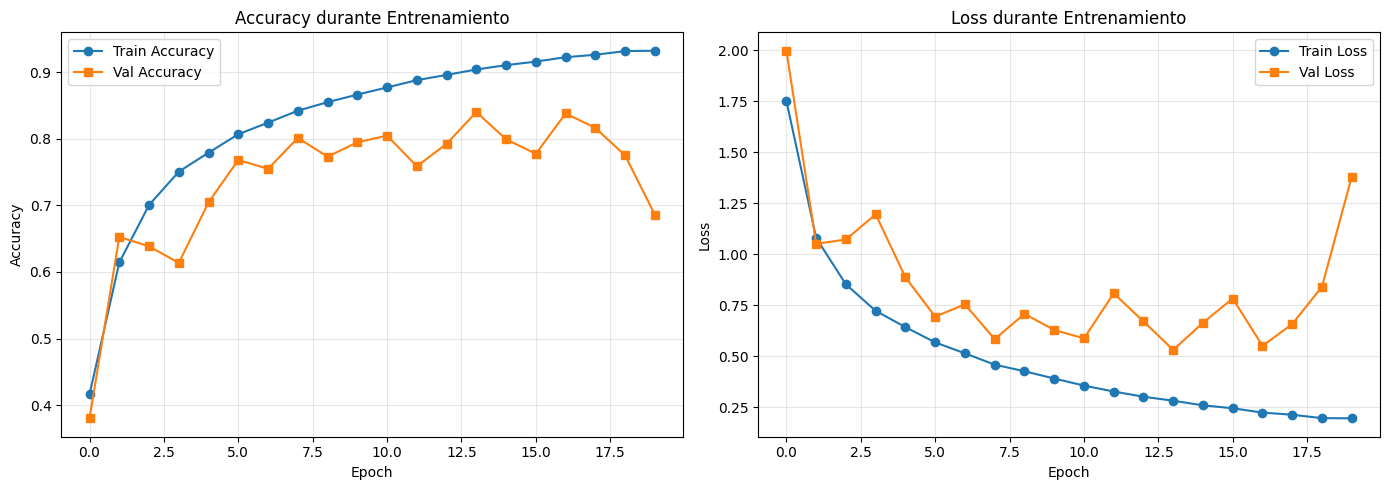


📋 DISTRIBUCIÓN DE CLASES EN TRAINING:
   Clase 0:  4800 muestras ( 10.0%)
   Clase 1:  4800 muestras ( 10.0%)
   Clase 2:  4800 muestras ( 10.0%)
   Clase 3:  4800 muestras ( 10.0%)
   Clase 4:  4800 muestras ( 10.0%)
   Clase 5:  4800 muestras ( 10.0%)
   Clase 6:  4800 muestras ( 10.0%)
   Clase 7:  4800 muestras ( 10.0%)
   Clase 8:  4800 muestras ( 10.0%)
   Clase 9:  4800 muestras ( 10.0%)

💡 INTERPRETACIÓN:
   ✓ Si las curvas convergen: modelo generaliza bien
   ✓ Si val_accuracy > train_accuracy al inicio: normalización correcta
   ⚠️  Si val_loss aumenta después: early stopping funcionó correctamente



In [41]:
# Análisis detallado del modelo CNN
import matplotlib.pyplot as plt

print('\n' + '='*70)
print('📈 ANÁLISIS DE CURVAS DE APRENDIZAJE - CNN')
print('='*70)

# Crear gráficas de training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_title('Accuracy durante Entrenamiento')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(history.history['loss'], label='Train Loss', marker='o')
ax2.plot(history.history['val_loss'], label='Val Loss', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Loss durante Entrenamiento')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('\n📋 DISTRIBUCIÓN DE CLASES EN TRAINING:')
unique_classes, counts = np.unique(y_train, return_counts=True)
for cls, cnt in zip(unique_classes, counts):
    pct = cnt / len(y_train) * 100
    print(f'   Clase {cls}: {cnt:5d} muestras ({pct:5.1f}%)')

print('\n💡 INTERPRETACIÓN:')
print('   ✓ Si las curvas convergen: modelo generaliza bien')
print('   ✓ Si val_accuracy > train_accuracy al inicio: normalización correcta')
print('   ⚠️  Si val_loss aumenta después: early stopping funcionó correctamente')

print('\n' + '='*70)

## Métricas finales (resumen)
Mostramos un reporte de clasificación en el conjunto de validación para evaluación académica.


🔮 GENERANDO PREDICCIONES DEL MODELO CNN...

📊 CLASSIFICATION REPORT - MODELO CNN:
              precision    recall  f1-score   support

    airplane     0.8682    0.8450    0.8564      1200
  automobile     0.9397    0.9217    0.9306      1200
        bird     0.8535    0.7183    0.7801      1200
         cat     0.6961    0.7483    0.7213      1200
        deer     0.8540    0.7992    0.8257      1200
         dog     0.7545    0.7658    0.7601      1200
        frog     0.8855    0.8633    0.8743      1200
       horse     0.8543    0.8992    0.8762      1200
        ship     0.7996    0.9508    0.8687      1200
       truck     0.9229    0.8875    0.9048      1200

    accuracy                         0.8399     12000
   macro avg     0.8428    0.8399    0.8398     12000
weighted avg     0.8428    0.8399    0.8398     12000


📈 MATRIZ DE CONFUSIÓN:


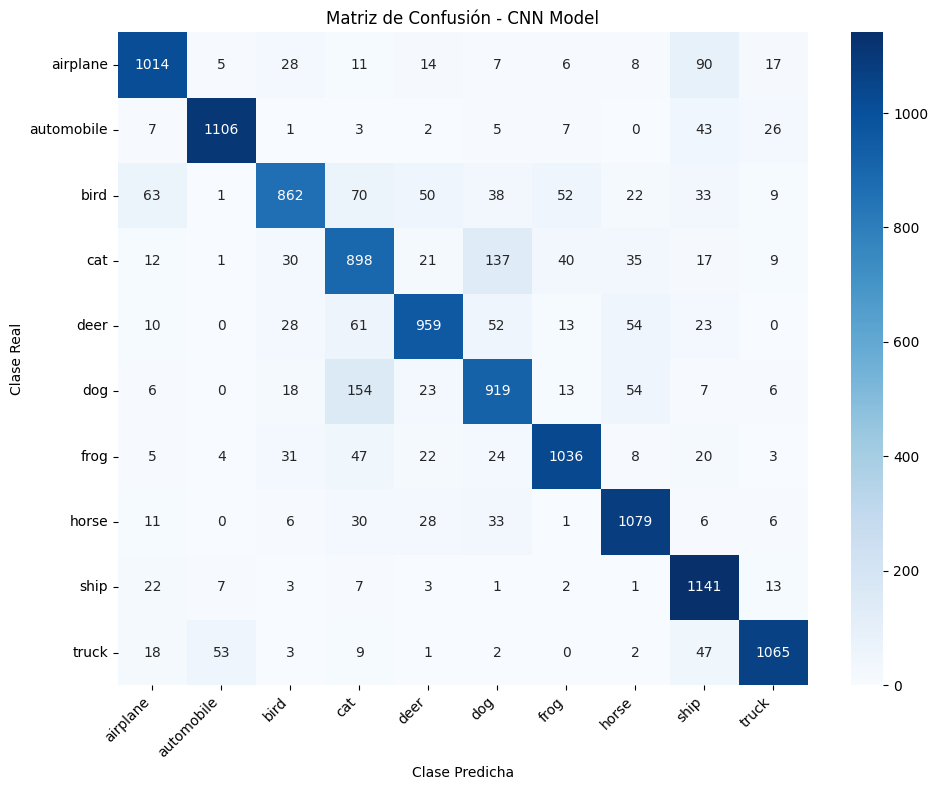


🎯 ACCURACY POR CLASE:
   airplane    : 84.50%
   automobile  : 92.17%
   bird        : 71.83%
   cat         : 74.83%
   deer        : 79.92%
   dog         : 76.58%
   frog        : 86.33%
   horse       : 89.92%
   ship        : 95.08%
   truck       : 88.75%



In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Etiquetas de CIFAR-10 para mejor legibilidad
cifar_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# GENERAR PREDICCIONES DEL MODELO CNN ACTUAL
print('\n' + '='*70)
print('🔮 GENERANDO PREDICCIONES DEL MODELO CNN...')
print('='*70)

y_val_pred_proba = model.predict(X_val_cnn, verbose=0)
y_val_pred = np.argmax(y_val_pred_proba, axis=1)

print('\n📊 CLASSIFICATION REPORT - MODELO CNN:')
print(classification_report(y_val, y_val_pred, target_names=cifar_labels, digits=4, zero_division=0))

# Matriz de confusión
print('\n📈 MATRIZ DE CONFUSIÓN:')
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=cifar_labels, yticklabels=cifar_labels)
plt.title('Matriz de Confusión - CNN Model')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Análisis por clase
print('\n🎯 ACCURACY POR CLASE:')
for i, label in enumerate(cifar_labels):
    mask = y_val == i
    if mask.sum() > 0:
        class_acc = (y_val_pred[mask] == y_val[mask]).mean() * 100
        print(f'   {label:12s}: {class_acc:5.2f}%')

print('\n' + '='*70)

**Fin del cuaderno 02.** No se realizan predicciones finales aquí; el modelo guardado será usado en el cuaderno 03.